# 01 · EDA Temporal

Objetivo (PDF sección 3.2): explorar la evolución temporal de las variables del dataset IEEE-CIS, identificar patrones, cambios de distribución y posibles anomalías.

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import matplotlib.pyplot as plt

from data import load_transaction_data
from features import add_time_features

df = load_transaction_data()
df = add_time_features(df)
df['week'] = df['day'] // 7

print('shape:', df.shape)
print('n_days:', df['day'].max() + 1, ' n_weeks:', df['week'].max() + 1)

shape: (590540, 438)
n_days: 182  n_weeks: 26


## 1. Volumen y tasa de fraude por semana

      n_txn  fraud_rate
week                   
0     27596    0.029135
1     28463    0.025191
2     35701    0.024341
3     34906    0.020741
4     24539    0.036228
      n_txn  fraud_rate
week                   
21    21443    0.030779
22    19811    0.028520
23    21038    0.034652
24    19941    0.036758
25    17752    0.042080
fraud_rate std entre semanas: 0.006929374894863063
fraud_rate min/max: 0.02074141981321263 0.05071638675396148


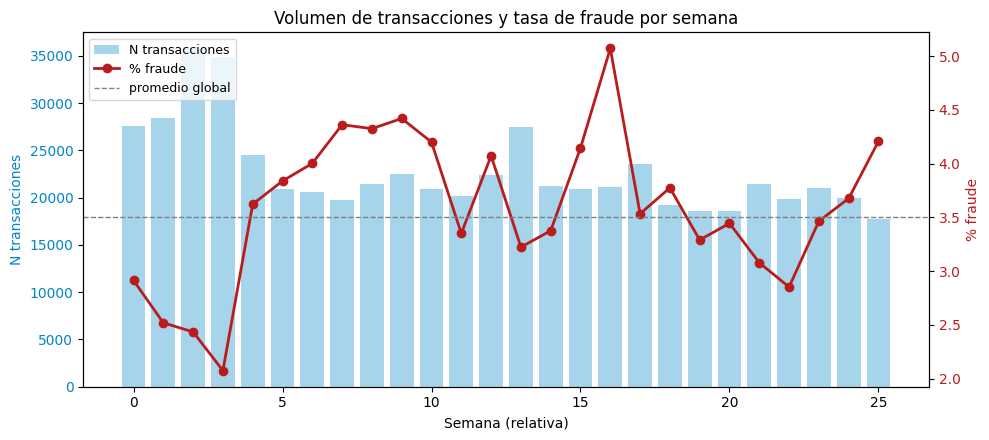

In [2]:
weekly = df.groupby('week').agg(n_txn=('isFraud', 'size'), fraud_rate=('isFraud', 'mean'))
print(weekly.head(5))
print(weekly.tail(5))
print('fraud_rate std entre semanas:', weekly['fraud_rate'].std())
print('fraud_rate min/max:', weekly['fraud_rate'].min(), weekly['fraud_rate'].max())

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(weekly.index, weekly['n_txn'], color='#0284c7', alpha=0.35, label='N transacciones')
ax1.set_xlabel('Semana (relativa)')
ax1.set_ylabel('N transacciones', color='#0284c7')
ax1.tick_params(axis='y', labelcolor='#0284c7')

ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly['fraud_rate'] * 100, marker='o', color='#b91c1c', linewidth=2, label='% fraude')
ax2.axhline(df['isFraud'].mean() * 100, color='gray', linestyle='--', linewidth=1, label='promedio global')
ax2.set_ylabel('% fraude', color='#b91c1c')
ax2.tick_params(axis='y', labelcolor='#b91c1c')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
ax1.set_title('Volumen de transacciones y tasa de fraude por semana')
plt.tight_layout()
plt.savefig('../figures/01_weekly_volume_fraud_rate.png', dpi=110)
plt.show()

![Volumen y tasa de fraude por semana](../figures/01_weekly_volume_fraud_rate.png)

La tasa de fraude semanal fluctúa entre 2.07% y 5.07% (la desviación estándar es de casi 0.7 puntos porcentuales) y muestra una tendencia ascendente hacia el final del periodo, de casi 2.9% en la semana 0 a 4.2% en la semana 25. Esto confirma con datos reales que el dataset no es estacionario, tal como se planteó en el objetivo específico 1 y en la justificación del dataset del checkpoint 1.

## 2. Estacionalidad: día de la semana y hora del día

             n_txn  fraud_rate
day_of_week                   
0            98502    0.036040
1            79834    0.037115
2            70223    0.035644
3            85433    0.031452
4            84815    0.033048
5            85356    0.034514
6            86377    0.037174
             n_txn  fraud_rate
hour_of_day                   
0            37795    0.031380
1            32797    0.031314
2            26732    0.037483
3            20802    0.038314
4            14839    0.051890
5             9701    0.070302
6             6007    0.077743
7             3704    0.106102
8             2591    0.093014
9             2479    0.089956
10            3627    0.053212
11            6827    0.038816
12           12451    0.030439
13           20315    0.022889
14           28328    0.024216
15           33859    0.025399
16           38698    0.029511
17           40723    0.031530
18           41639    0.035231
19           42115    0.034738
20           41782    0.034273
21      

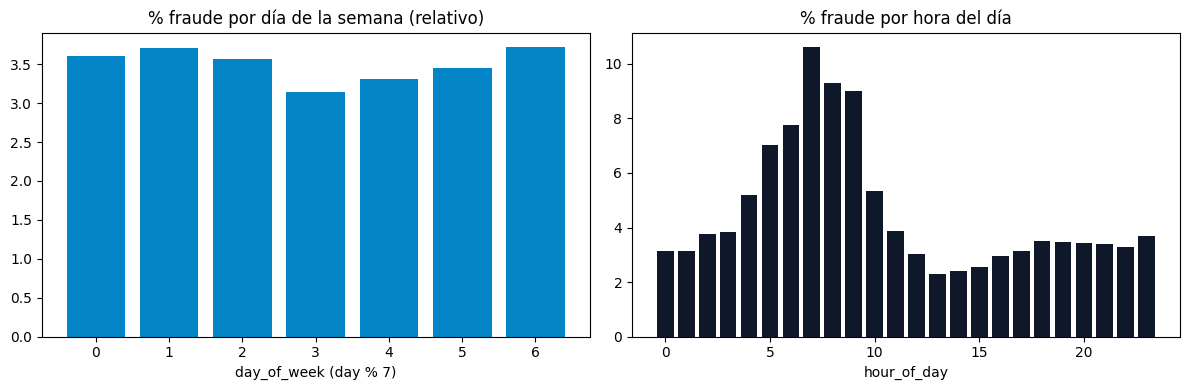

In [3]:
dow = df.groupby('day_of_week').agg(n_txn=('isFraud', 'size'), fraud_rate=('isFraud', 'mean'))
hod = df.groupby('hour_of_day').agg(n_txn=('isFraud', 'size'), fraud_rate=('isFraud', 'mean'))
print(dow)
print(hod)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(dow.index, dow['fraud_rate'] * 100, color='#0284c7')
axes[0].set_title('% fraude por día de la semana (relativo)')
axes[0].set_xlabel('day_of_week (day % 7)')
axes[1].bar(hod.index, hod['fraud_rate'] * 100, color='#0f172a')
axes[1].set_title('% fraude por hora del día')
axes[1].set_xlabel('hour_of_day')
plt.tight_layout()
plt.savefig('../figures/02_seasonality_dow_hour.png', dpi=110)
plt.show()

![Estacionalidad](../figures/02_seasonality_dow_hour.png)

El día de la semana no muestra mucha variación (entre 3.1% y 3.7%), pero la hora del día sí. La tasa de fraude se dispara entre las 5 y las 9 de la mañana, llegando a 10.6% en la hora 7, aunque en esas horas hay poco volumen de transacciones legítimas. Puede ser una variable útil para el módulo predictivo (checkpoint 1, sección 4).

## 3. Distribución de `TransactionAmt` en el tiempo

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64
            mean  median         std
week                                
0     130.977197   68.95  220.586459
1     127.254691   69.31  208.552548
2     132.375371   82.95  193.215344
3     119.312712   75.00  174.708332
4     132.301100   65.00  211.208650
            mean  median         std
week                                
21    139.044031  72.950  235.511357
22    136.176867  67.950  241.700513
23    133.272205  67.950  243.832688
24    135.500302  70.702  239.173246
25    142.245258  68.500  263.485399


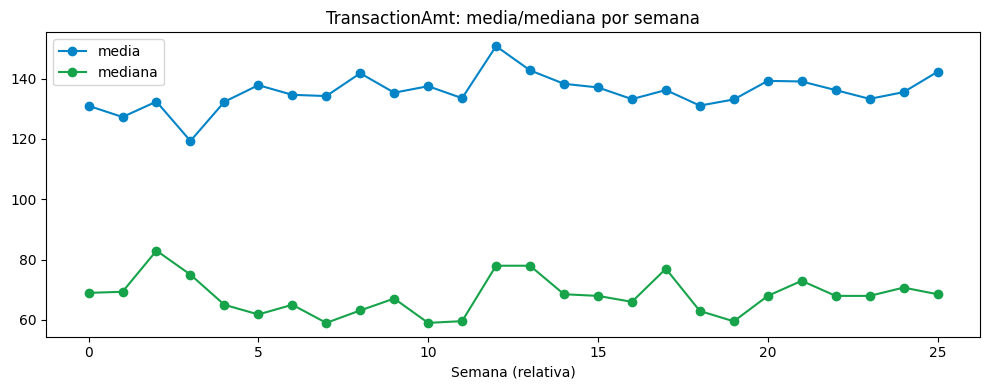

In [4]:
print(df['TransactionAmt'].describe())
amt_weekly = df.groupby('week')['TransactionAmt'].agg(['mean', 'median', 'std'])
print(amt_weekly.head(5))
print(amt_weekly.tail(5))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(amt_weekly.index, amt_weekly['mean'], marker='o', label='media', color='#0284c7')
ax.plot(amt_weekly.index, amt_weekly['median'], marker='o', label='mediana', color='#16a34a')
ax.set_title('TransactionAmt: media/mediana por semana')
ax.set_xlabel('Semana (relativa)')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/03_amount_over_time.png', dpi=110)
plt.show()

![Monto en el tiempo](../figures/03_amount_over_time.png)

El monto promedio se mantiene bastante estable, entre 120 y 142 dólares, a lo largo de las 26 semanas, aunque la dispersión crece un poco hacia el final del periodo.

## 4. Cambio de distribución en variables categóricas (drift de entrada)

In [5]:
n_weeks = df['week'].max() + 1
first_half = df[df['week'] < n_weeks / 2]
second_half = df[df['week'] >= n_weeks / 2]

productcd_shift = pd.DataFrame({
    'primera_mitad_%': first_half['ProductCD'].value_counts(normalize=True) * 100,
    'segunda_mitad_%': second_half['ProductCD'].value_counts(normalize=True) * 100,
}).round(2)
print('ProductCD:')
print(productcd_shift)

card4_shift = pd.DataFrame({
    'primera_mitad_%': first_half['card4'].value_counts(normalize=True) * 100,
    'segunda_mitad_%': second_half['card4'].value_counts(normalize=True) * 100,
}).round(2)
print('card4 (marca de tarjeta):')
print(card4_shift)

ProductCD:
           primera_mitad_%  segunda_mitad_%
ProductCD                                  
W                    69.71            80.06
C                    11.82            11.35
R                     8.52             3.86
H                     8.10             2.62
S                     1.85             2.11
card4 (marca de tarjeta):
                  primera_mitad_%  segunda_mitad_%
card4                                             
american express             1.90             0.84
discover                     1.22             1.02
mastercard                  31.26            33.16
visa                        65.62            64.98


ProductCD cambia bastante entre la primera y la segunda mitad del periodo. La categoría W pasa de 69.7% a 80.1% de las transacciones, mientras que R cae de 8.5% a 3.9% y H de 8.1% a 2.6%. En card4, American Express se reduce casi a la mitad, de 1.9% a 0.8%. Esto es evidencia directa de drift en la distribución de entrada, algo a considerar tanto en el preprocesamiento (notebook 02) como en la detección de drift (notebook 05).

## 5. Cobertura de datos de identidad en el tiempo

C:\Users\USER\AppData\Local\Temp\ipykernel_42636\3030118328.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  id_coverage_weekly = df.groupby('week').apply(lambda g: g['id_01'].notna().mean() * 100)


week
0    27.152486
1    40.301444
2    50.233887
3    54.512118
4    23.330209
dtype: float64
week
21    16.382969
22    19.342789
23    25.843711
24    23.143273
25    18.578188
dtype: float64


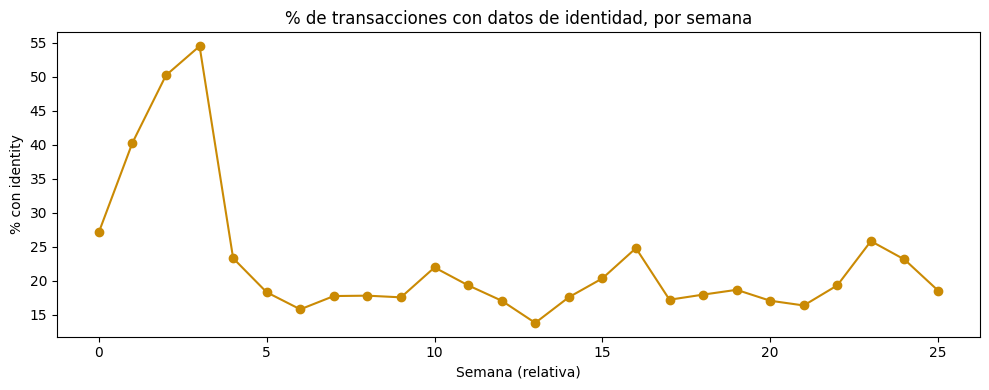

In [6]:
id_coverage_weekly = df.groupby('week').apply(lambda g: g['id_01'].notna().mean() * 100)
print(id_coverage_weekly.head(5))
print(id_coverage_weekly.tail(5))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(id_coverage_weekly.index, id_coverage_weekly.values, marker='o', color='#ca8a04')
ax.set_title('% de transacciones con datos de identidad, por semana')
ax.set_xlabel('Semana (relativa)')
ax.set_ylabel('% con identity')
plt.tight_layout()
plt.savefig('../figures/04_identity_coverage_over_time.png', dpi=110)
plt.show()

![Cobertura de identity](../figures/04_identity_coverage_over_time.png)

La cobertura de identity no es estable. Sube fuerte en las primeras semanas (27%, 40%, 50%, 54% en las semanas 0 a 3) y después cae de golpe a partir de la semana 4, quedando en un rango mucho más bajo, entre 15% y 26%, durante el resto del periodo. Es un cambio brusco y no una tendencia gradual, probablemente porque cambió algo en cómo o cuándo se recolectaban los datos de identidad. Esto refuerza la restricción de información mínima garantizada del checkpoint 1: el sistema no puede depender de que los datos de identidad estén siempre disponibles.

## 6. Anomalías y calidad de datos

In [7]:
print('TransactionID duplicados:', df['TransactionID'].duplicated().sum())
print('TransactionAmt <= 0:', (df['TransactionAmt'] <= 0).sum())
print('TransactionAmt top 10 mas altos:')
print(df['TransactionAmt'].sort_values(ascending=False).head(10).tolist())

null_pct = df.isna().mean().sort_values(ascending=False)
print('Top 15 columnas con mas nulos (%):')
print((null_pct.head(15) * 100).round(1))
print('Columnas con 0% nulos:', (null_pct == 0).sum(), 'de', len(null_pct))

TransactionID duplicados: 0
TransactionAmt <= 0: 0
TransactionAmt top 10 mas altos:
[31937.391, 31937.391, 6450.97, 6085.23, 5543.23, 5420.0, 5420.0, 5366.82, 5279.95, 5279.95]


Top 15 columnas con mas nulos (%):
id_24    99.2
id_25    99.1
id_08    99.1
id_07    99.1
id_21    99.1
id_26    99.1
id_22    99.1
id_27    99.1
id_23    99.1
dist2    93.6
D7       93.4
id_18    92.4
D13      89.5
D14      89.5
D12      89.0
dtype: float64
Columnas con 0% nulos: 24 de 438


No hay TransactionID duplicados ni montos menores o iguales a 0. Sí aparecen 2 transacciones raras de $31,937.39, exactamente el mismo valor, que probablemente haya que winsorizar en el preprocesamiento. El dataset tiene bastante missingness: solo 24 de las 438 columnas no tienen ningún nulo, y 9 columnas de identity superan el 99% de nulos. Esto define la estrategia de imputación y selección de variables que se usa en el notebook 02.

## Conclusiones para las siguientes etapas

- Hay que respetar el split temporal sí o sí: como hay tendencia y variación por hora, no se puede asumir que los datos son independientes o que tienen la misma distribución entre periodos (esto es justamente la restricción de consistencia temporal del checkpoint 1).
- ProductCD y card4 muestran un drift real en su distribución, así que conviene monitorearlos en el notebook 05 y no fijarse solo en el rendimiento del modelo.
- hour_of_day parece una variable predictiva relevante, vale la pena incluirla en el notebook 02.
- La cobertura de identity baja con el tiempo, así que el modelo no debería depender demasiado de las variables id_* recientes, que tienen mucho nulo.
- Hay que definir una estrategia para los outliers de TransactionAmt (winsorizar o capear los valores extremos) en el notebook 02.
- La tendencia ascendente de la tasa de fraude junto con el cambio de mix de ProductCD son evidencia concreta del drift mixto (gradual y por campañas) que planteamos en la justificación del dataset del checkpoint 1.